In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/raw/historical_data.csv")
print(df.shape)
df.head()

(197428, 16)


,market_id,created_at,actual_delivery_time,store_id,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_order_place_duration,estimated_store_to_consumer_driving_duration
0,1.0,2015-02-06 22:24:17,2015-02-06 23:27:16,1845,american,1.0,4,3441,4,557,1239,33.0,14.0,21.0,446,861.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:56:29,5477,mexican,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,446,690.0
2,3.0,2015-01-22 20:39:28,2015-01-22 21:09:09,5477,NaN,1.0,1,1900,1,1900,1900,1.0,0.0,0.0,446,690.0
3,3.0,2015-02-03 21:21:45,2015-02-03 22:13:00,5477,NaN,1.0,6,6900,5,600,1800,1.0,1.0,2.0,446,289.0
4,3.0,2015-02-15 02:40:36,2015-02-15 03:20:26,5477,NaN,1.0,3,3900,3,1100,1600,6.0,6.0,9.0,446,650.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 197428 entries, 0 to 197427
Data columns (total 16 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     196441 non-null  float64
 1   created_at                                    197428 non-null  str    
 2   actual_delivery_time                          197421 non-null  str    
 3   store_id                                      197428 non-null  int64  
 4   store_primary_category                        192668 non-null  str    
 5   order_protocol                                196433 non-null  float64
 6   total_items                                   197428 non-null  int64  
 7   subtotal                                      197428 non-null  int64  
 8   num_distinct_items                            197428 non-null  int64  
 9   min_item_price                                197428 non-nu

In [5]:
df.isna().sum()

market_id                                         987
created_at                                          0
actual_delivery_time                                7
store_id                                            0
store_primary_category                           4760
order_protocol                                    995
total_items                                         0
subtotal                                            0
num_distinct_items                                  0
min_item_price                                      0
max_item_price                                      0
total_onshift_dashers                           16262
total_busy_dashers                              16262
total_outstanding_orders                        16262
estimated_order_place_duration                      0
estimated_store_to_consumer_driving_duration      526
dtype: int64

In [6]:
df.describe()

,market_id,store_id,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_order_place_duration,estimated_store_to_consumer_driving_duration
count,196441.000000,197428.000000,196433.000000,197428.000000,197428.000000,197428.000000,197428.000000,197428.000000,181166.000000,181166.000000,181166.000000,197428.000000,196902.000000
mean,2.978706,3530.510272,2.882352,3.196391,2682.331402,2.670791,686.218470,1159.588630,44.808093,41.739747,58.050065,308.560179,545.358935
std,1.524867,2053.496711,1.503771,2.666546,1823.093688,1.630255,522.038648,558.411377,34.526783,32.145733,52.661830,90.139653,219.352902
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,-86.000000,0.000000,-4.000000,-5.000000,-6.000000,0.000000,0.000000
25%,2.000000,1686.000000,1.000000,2.000000,1400.000000,1.000000,299.000000,800.000000,17.000000,15.000000,17.000000,251.000000,382.000000
50%,3.000000,3592.000000,3.000000,3.000000,2200.000000,2.000000,595.000000,1095.000000,37.000000,34.000000,41.000000,251.000000,544.000000
75%,4.000000,5299.000000,4.000000,4.000000,3395.000000,3.000000,949.000000,1395.000000,65.000000,62.000000,85.000000,446.000000,702.000000
max,6.000000,6987.000000,7.000000,411.000000,27100.000000,20.000000,14700.000000,14700.000000,171.000000,154.000000,285.000000,2715.000000,2088.000000


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["created_at"] = pd.to_datetime(df["created_at"])
df["actual_delivery_time"] = pd.to_datetime(df["actual_delivery_time"])

In [9]:
df["duration_min"] = (df["actual_delivery_time"] - df["created_at"]).dt.total_seconds() / 60

df["duration_min"].describe()

count    197421.000000
mean         48.470956
std         320.493482
min           1.683333
25%          35.066667
50%          44.333333
75%          56.350000
max      141947.650000
Name: duration_min, dtype: float64

In [10]:
df["hour"] = df["created_at"].dt.hour
df["weekday"] = df["created_at"].dt.dayofweek

df[["created_at", "hour", "weekday", "duration_min"]].head()

C:\Users\Vikas\AppData\Local\Temp\ipykernel_21888\3730474410.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["weekday"] = df["created_at"].dt.dayofweek


,created_at,hour,weekday,duration_min
0,2015-02-06 22:24:17,22,4,62.983333
1,2015-02-10 21:49:25,21,1,67.066667
2,2015-01-22 20:39:28,20,3,29.683333
3,2015-02-03 21:21:45,21,1,51.250000
4,2015-02-15 02:40:36,2,6,39.833333


In [11]:
# how many deliveries are extreme?
print("over 180 min:", (df["duration_min"] > 180).sum())
print("under or equal 0:", (df["duration_min"] <= 0).sum())
print("negative dasher counts:")
print((df[["total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders"]] < 0).sum())

over 180 min: 138
under or equal 0: 0
negative dasher counts:
total_onshift_dashers       21
total_busy_dashers          21
total_outstanding_orders    44
dtype: int64


In [12]:
rows_before = len(df)

# drop rows with no delivery time
df = df.dropna(subset=["actual_delivery_time"])

# keep only deliveries between 0 and 180 minutes
df = df[(df["duration_min"] > 0) & (df["duration_min"] <= 180)]

print("rows removed:", rows_before - len(df))
print("rows left:", len(df))

rows removed: 145
rows left: 197283


In [13]:
# negative counts are impossible, so make them empty
for col in ["total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders"]:
    df.loc[df[col] < 0, col] = np.nan

In [14]:
# if a store has a known category in other rows, reuse it
store_category = df.groupby("store_id")["store_primary_category"].agg(
    lambda s: s.mode().iloc[0] if s.notna().any() else np.nan
)
df["store_primary_category"] = df["store_primary_category"].fillna(df["store_id"].map(store_category))

# anything still empty becomes "unknown"
df["store_primary_category"] = df["store_primary_category"].fillna("unknown")
df["market_id"] = df["market_id"].fillna(0)
df["order_protocol"] = df["order_protocol"].fillna(0)

In [15]:
# add a flag so the model knows these were missing
df["dasher_info_missing"] = df["total_onshift_dashers"].isna().astype(int)

# fill with the middle value (median)
for col in ["total_onshift_dashers", "total_busy_dashers",
            "total_outstanding_orders",
            "estimated_store_to_consumer_driving_duration"]:
    df[col] = df[col].fillna(df[col].median())

In [16]:
print(df.isna().sum().sum(), "empty values left")
print(df["duration_min"].describe())

df.to_csv("../data/processed/clean.csv", index=False)
print(df.shape)

0 empty values left
count    197283.000000
mean         47.533562
std          18.041246
min           1.683333
25%          35.066667
50%          44.316667
75%          56.316667
max         179.850000
Name: duration_min, dtype: float64
(197283, 20)


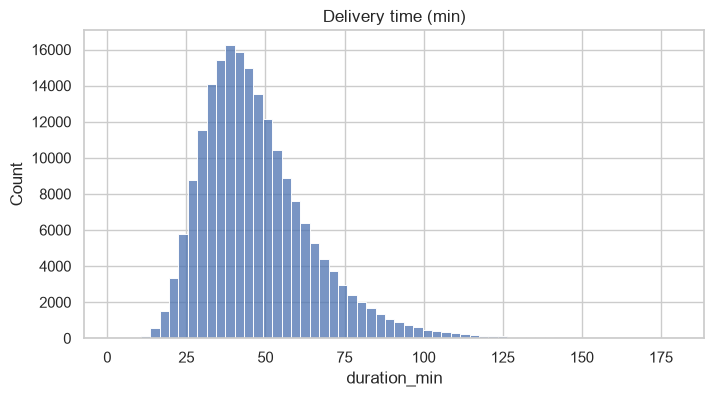

In [17]:
# how long deliveries take
plt.figure(figsize=(8, 4))
sns.histplot(df["duration_min"], bins=60)
plt.title("Delivery time (min)")
plt.savefig("../reports/01_duration_distribution.png", dpi=150)
plt.show()

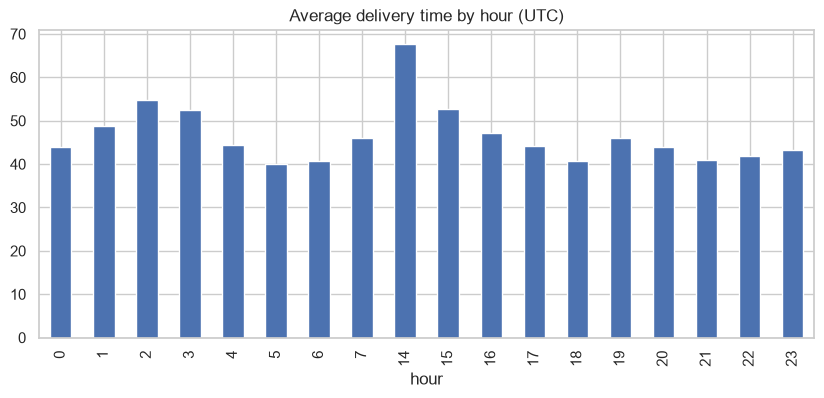

In [18]:
# average delivery time for each hour (UTC)
plt.figure(figsize=(10, 4))
df.groupby("hour")["duration_min"].mean().plot(kind="bar")
plt.title("Average delivery time by hour (UTC)")
plt.savefig("../reports/02_duration_by_hour.png", dpi=150)
plt.show()

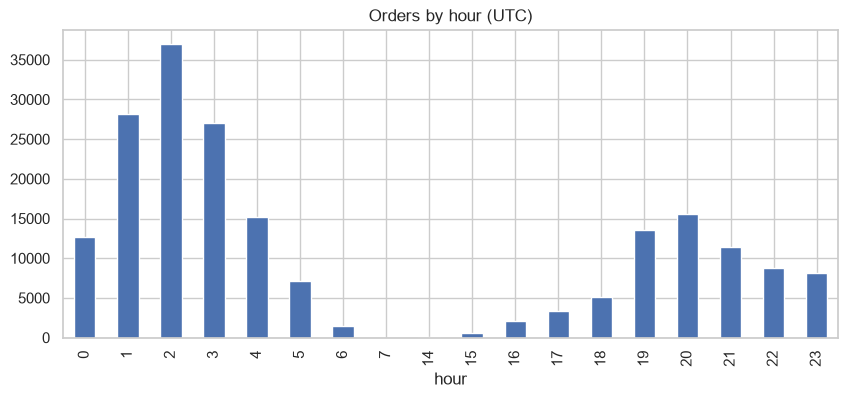

In [19]:
# number of orders per hour (shows peak times)
plt.figure(figsize=(10, 4))
df["hour"].value_counts().sort_index().plot(kind="bar")
plt.title("Orders by hour (UTC)")
plt.savefig("../reports/03_orders_by_hour.png", dpi=150)
plt.show()

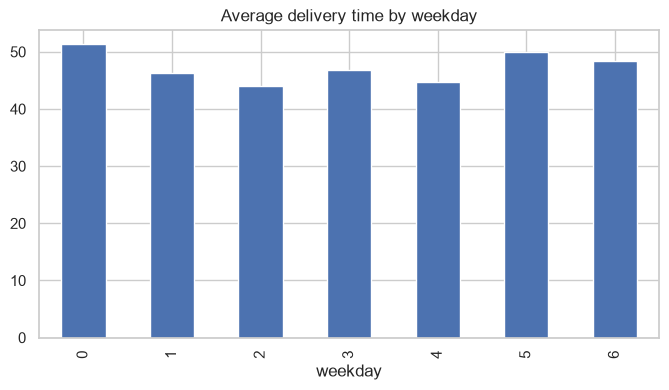

In [20]:
# 0 = Monday, 6 = Sunday
plt.figure(figsize=(8, 4))
df.groupby("weekday")["duration_min"].mean().plot(kind="bar")
plt.title("Average delivery time by weekday")
plt.savefig("../reports/04_duration_by_weekday.png", dpi=150)
plt.show()

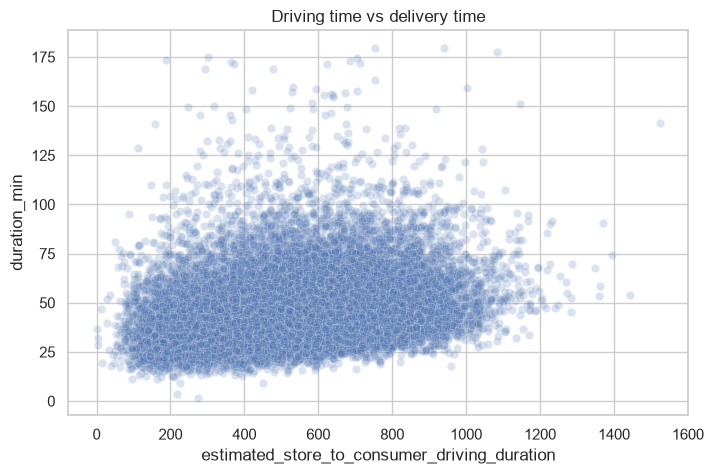

In [21]:
# use a sample so the plot is fast
sample = df.sample(20000, random_state=42)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="estimated_store_to_consumer_driving_duration",
                y="duration_min", alpha=0.2)
plt.title("Driving time vs delivery time")
plt.savefig("../reports/05_driving_vs_duration.png", dpi=150)
plt.show()

In [22]:
# busy ratio = busy dashers / on-shift dashers
df["busy_ratio"] = df["total_busy_dashers"] / df["total_onshift_dashers"].replace(0, np.nan)
df["busy_ratio"] = df["busy_ratio"].fillna(df["busy_ratio"].median())

# average delivery time for each busy-ratio group
df.groupby(pd.cut(df["busy_ratio"], [0, 0.5, 0.8, 1, 1.5, 100]))["duration_min"].mean()

busy_ratio
(0.0, 0.5]      39.926857
(0.5, 0.8]      42.300475
(0.8, 1.0]      48.952439
(1.0, 1.5]      49.870326
(1.5, 100.0]    42.869336
Name: duration_min, dtype: float64

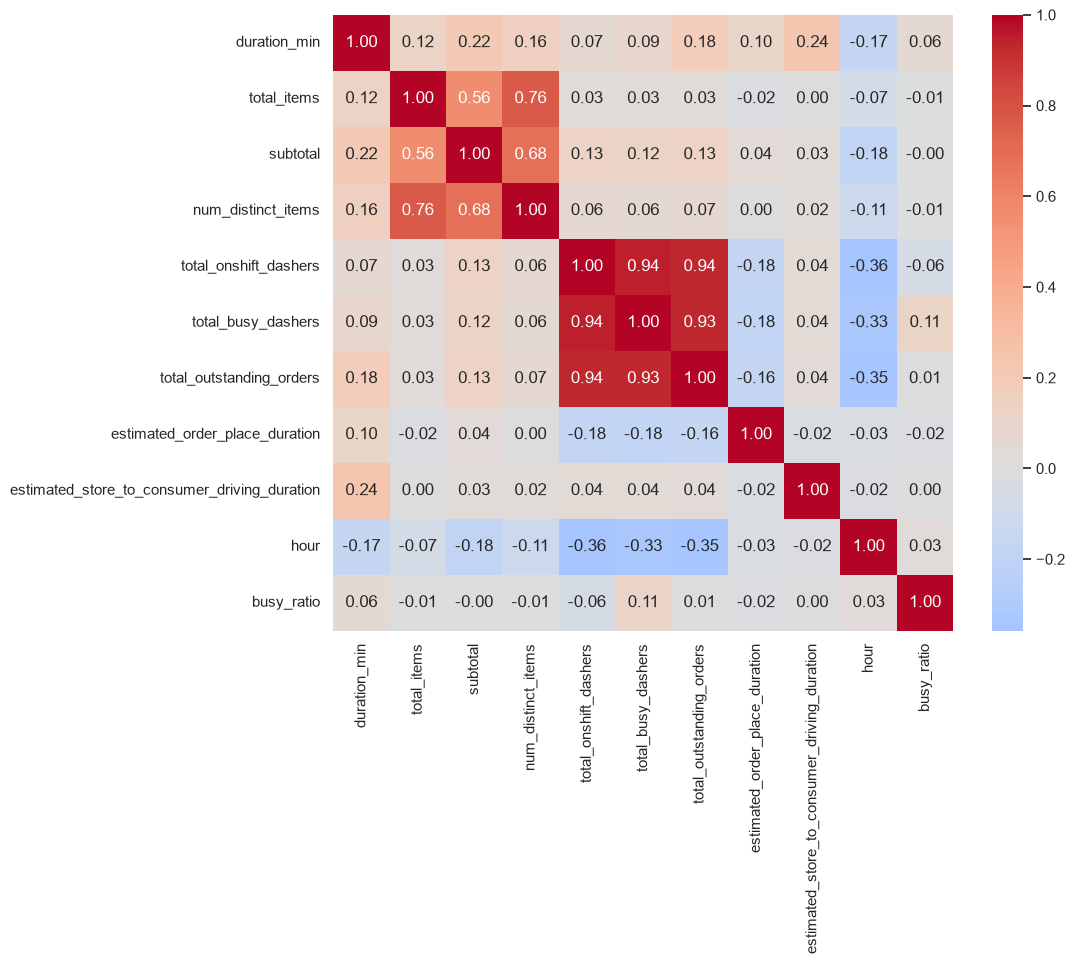

In [23]:
# which numbers move together with delivery time
cols = ["duration_min", "total_items", "subtotal", "num_distinct_items",
        "total_onshift_dashers", "total_busy_dashers", "total_outstanding_orders",
        "estimated_order_place_duration",
        "estimated_store_to_consumer_driving_duration", "hour", "busy_ratio"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.savefig("../reports/06_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

## Day 1 Findings


1. Median delivery time is about 44 minutes. Most deliveries take between 35 and 56 minutes.
2. Longer driving time means longer delivery time (correlation 0.24). Average delivery time rises from 42.0 min for the shortest drives to 53.0 min for the longest, but the dots are spread wide, so driving time alone does not explain everything.
3. Among hours with many orders, deliveries are slowest at hour 2 (UTC, 54.7 min) and fastest at hour 5 (40.0 min). Hours 14 and 15 look slower still, but they have only 40 and 537 orders, so their averages are unreliable.
4. The busiest ordering hours are 2, 1 and 3 (UTC), with about 37k, 28k and 27k orders. These are likely evening hours in US time zones.
5. When the busy ratio rises from below 0.5 to between 0.8 and 1.5, average delivery time goes from 41.3 min to about 49 min. For very high ratios (above 1.5) the average drops back to 41.9 min, so the effect is not a straight line.
6. Rows with missing dasher info have an average delivery time of 47.4 min vs 47.5 min for other rows, so missing data made no visible difference by itself.
7. Data errors (deliveries over 180 minutes) were removed: 145 rows, about 0.07%.